# Edge knot-shift comparison

Spline fits at several knot-count shifts, overlaid with the mtanh fit, for one interval. Everything is fitted here from the raw TS data, with settings from `pipeline_config_run05_new_outlier.yaml`. No saved fit files are read. In the overlay, circles in rows below zero mark the knots, one row per shift, coloured like its spline.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml

sys.path.insert(0, str(Path.cwd().resolve().parents[0] / 'src'))
sys.path.insert(0, '/shares/users/work/joanune/Desktop/pysepest')
sys.path.insert(0, '/shares/users/work/joanune/Desktop/aug_separatrix')

from ipfnpytools.plot import plots as ipfn_plots
from ipfnpytools.plot import use_base_style
from get_connection_length import get_LcSOL
from pysepest.optimizers import first_0_crossing
from ts_profile_fitter.derived_quantities import (
    compute_equilibrium_separatrix,
    compute_physics_separatrix,
    get_connection_length,
)
from ts_profile_fitter.figure_naming import make_fig_name
from ts_profile_fitter.fit_metrics import compute_fit_metrics
from ts_profile_fitter.fitting import (
    compute_channel_knots,
    count_modified_tanh_parameters,
    fit_ipfn_spline_ne_Te_TS,
    fit_modified_tanh_profile,
    modified_tanh,
)
from ts_profile_fitter.loading import load_intervals, load_physics_inputs, load_ts_data
from ts_profile_fitter.plotting import plot_profile_summary
from ts_profile_fitter.preprocess import (
    apply_cold_dense_edge_filters,
    apply_density_outside_separatrix_filter,
    map_to_r_midplane,
    preprocess_ts_data,
    augment_measurement_errors,
)

#use_base_style()


01:29:36 | aug_sfutils | INFO: Using version 0.9.5
01:29:36 | aug_sfutils.mapeq | INFO: AUG-SF home /shares/software/aug-dv/moduledata/miniforge3/2024.09/lib/python3.10/site-packages/aug_sfutils


## Config and preprocess

In [2]:
config_path = Path.cwd().resolve().parent / 'configs' / 'pipeline_config_experiment.yaml'
with config_path.open('r', encoding='utf-8') as stream:
    pipeline_config = yaml.safe_load(stream)


def resolve_config_path(key):
    path = Path(pipeline_config[key])
    return path if path.is_absolute() else config_path.parent / path


fit_config = pipeline_config['fit_config']
preprocess_config = fit_config['preprocess']
spline_config = fit_config['fits']['spline']
mtanh_config = fit_config['fits']['mtanh']
physics_config = fit_config['physics']
assert spline_config['method'] == 'ipfn_spline', 'Pinned spline method must be ipfn_spline'

equilibrium = pipeline_config['equilibrium']
data_directory = str(resolve_config_path('data_dir'))
intervals_path = str(resolve_config_path('database'))
output_directory = config_path.parents[1] / 'plots'

shot_id = 38067
time_requested = 6.62 # any time inside the wanted interval
BASE_KNOT_COUNT_SHIFT = int(spline_config['knot_count_shift'])
KNOT_COUNT_SHIFTS = sorted({-2, 0, +2,+4} | {BASE_KNOT_COUNT_SHIFT})  # edit to choose; base is always included
R_ZOOM, R_ZOOM_MAX = 2.11, 2.20  # edge window used by the pinned notebook

te_error_config = {
    'enabled': True,
    'fixed_error': 20,  # eV
    'relative_error': 0,  # fraction, not percent
    'source_column': 'Te_err',
    'output_column': 'Te_err_augmented',
    'fit_error_column': 'Te_err_augmented',
}

print(f'Knot count shifts: {KNOT_COUNT_SHIFTS} (base {BASE_KNOT_COUNT_SHIFT})')

Knot count shifts: [-2, 0, 2, 4] (base 0)


In [3]:
intervals_df = load_intervals(intervals_path)
shot_intervals = intervals_df[intervals_df['shot_id'] == shot_id]
matching_intervals = shot_intervals[
    (shot_intervals['t_begin'] <= time_requested) & (time_requested <= shot_intervals['t_end'])
]
if matching_intervals.empty:
    raise ValueError(f'No interval for shot {shot_id} at t={time_requested:.3f} s.')
selected_interval = matching_intervals.iloc[0]
interval = {
    't_begin': float(selected_interval['t_begin']),
    't_end': float(selected_interval['t_end']),
    'label': selected_interval['label'],
}
print(f"Shot {shot_id}: ({interval['t_begin']:.3f}, {interval['t_end']:.3f}) s, {interval['label']}")

ts_dict = load_ts_data(shot_id=shot_id, data_dir=data_directory, equilibrium=equilibrium)
ts_df, preprocess_metadata = preprocess_ts_data(
    ts_dict,
    interval=interval,
    r_edge_offset=preprocess_config.get('r_edge_offset', 0.008),
    mapping_method=preprocess_config.get('mapping_method', 'ipfnpytools'),
    outlier_config=preprocess_config.get('outlier_config', {}),
    local_statistical_outlier_config=preprocess_config.get('local_statistical_outlier_config', {}),
    rhop_filter=preprocess_config.get('rhop_filter', {}),
    report_outliers=True,
    return_metadata=True,
)
ts_df, _ = apply_density_outside_separatrix_filter(
    ts_df,
    config=preprocess_config.get('density_outside_separatrix_config', {}),
    report=True,
    return_metadata=True,
)
ts_df, _ = apply_cold_dense_edge_filters(
    ts_df,
    cold_dense_config=preprocess_config.get('cold_dense_edge_config', {}),
    report=True,
    return_metadata=True,
)
ts_df = map_to_r_midplane(ts_df)

if te_error_config['enabled']:
    ts_df = augment_measurement_errors(
        ts_df,
        quantity='Te',
        error_column=te_error_config['source_column'],
        fixed_error=te_error_config['fixed_error'],
        relative_error=te_error_config['relative_error'],
        output_column=te_error_config['output_column'],
    )
    ts_df[te_error_config['source_column']] = ts_df[te_error_config['output_column']]
else:
    ts_df = ts_df.copy()
    ts_df[te_error_config['output_column']] = ts_df[te_error_config['source_column']]

df_te = ts_df[['r_midplane', 'Te', 'Te_err']].dropna().sort_values('r_midplane')
df_ne = ts_df[['r_midplane', 'Ne', 'Ne_err']].dropna().sort_values('r_midplane')

te_popt, _ = fit_modified_tanh_profile(
    df_te['r_midplane'].to_numpy(float),
    df_te['Te'].to_numpy(float),
    df_te['Te_err'].to_numpy(float),
    **mtanh_config['Te'],
)
ne_popt, _ = fit_modified_tanh_profile(
    df_ne['r_midplane'].to_numpy(float),
    df_ne['Ne'].to_numpy(float),
    df_ne['Ne_err'].to_numpy(float),
    **mtanh_config['Ne'],
)

Shot 38067: (6.616, 6.716) s, developed calm EDA H-mode (with QCM)


01:29:37 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/VTA/38/38067.1
01:29:37 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38067.1
01:29:37 | aug_sfutils.sf2equ | INFO: Reading equ scalars
01:29:37 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
01:29:39 | aug_sfutils.sf2equ | INFO: Reading equ PFM
01:29:39 | aug_sfutils.sf2equ | INFO: COCO 17


Dimensions before mapping: time: (691, 1) r: (691, 1) z: (1, 16)
Dimensions before mapping: time: (1181, 1) r: (1181, 1) z: (1, 11)


/u/joanune/ipfnpytools/ipfnpytools/trz_to_rhop.py:61: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), dtype=np.float32),
/u/joanune/ipfnpytools/ipfnpytools/trhopz_to_r.py:124: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.swapaxes(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), 0, 2), dtype=data_type),


[Measurement Validity Filtering Report]
  - Te_zero_value: 1103 points
  - Te_zero_error: 1103 points
  - Ne_zero_value: 1103 points
  - Ne_negative_value: 605 points
  - Ne_zero_error: 1103 points
[Local Statistical Outlier Report: core:Te]
Removed 60 rows; upper-value: 51, relative-error: 14, both: 5.
Skipped for insufficient support; upper-value: 15, relative-error: 15.
[Local Statistical Outlier Report: core:Ne]
Removed 71 rows; upper-value: 65, relative-error: 10, both: 4.
Skipped for insufficient support; upper-value: 15, relative-error: 15.
[Local Statistical Outlier Report: edge:Te]
Removed 1219 rows; upper-value: 938, relative-error: 364, both: 83.
Skipped for insufficient support; upper-value: 34, relative-error: 34.
[Local Statistical Outlier Report: edge:Ne]
Removed 456 rows; upper-value: 405, relative-error: 340, both: 289.
Skipped for insufficient support; upper-value: 34, relative-error: 34.
Removed 2 core TS channels (11 rows); removed 0 edge TS channels (0 rows).


## Labeling and stuff

In [4]:
import pandas as pd
filepath = '/shares/users/work/joanune/Desktop/ipfn_examples/lgileda/EDA H-mode AUG database.xlsx'
#filepath = os.path.join("lgileda", "EDA H-mode AUG database.xlsx")
data_periods = pd.read_excel(filepath)
labels = pd.read_excel(filepath, sheet_name='labels', header=None).to_numpy()[:,0]
shots = data_periods['shot'].unique()
merge_labels_dict_some = {
    labels[i]:label 
    for label, indices in zip(
        [
            'L-mode', 'I-phase', 'nonstationary ELM-free H-mode', 'evolving EDA H-mode', 'developed EDA H-mode', 
            'evolving ELMy H-mode', 'developed ELMy H-mode'], 
        [
            [0, 1], [2], np.r_[3:6], [6, 8, 9], np.r_[7, 10:13], np.r_[17, 19, 21, 22, 23, 25:28], 
            np.r_[13:17, 18, 20, 24, 28]])
    for i in indices}
merge_labels_some_name = 'merged label some'

merge_labels_dict = {
    labels[i]:label 
    for label, indices in zip(
        ['L-mode', 'I-phase', 'nonstationary ELM-free H-mode', 'EDA H-mode', 'ELMy H-mode'], 
        [[0], [1, 2], np.r_[3:6], np.r_[6:13], np.r_[13:29]])
    for i in indices}
merge_labels_name = 'merged label'

#TODO: define plot order for all labels, including non-merged
regime_plot_order_dict = {
    'L-mode':0, 'I-phase':1, 'nonstationary ELM-free H-mode':2, 'evolving ELMy H-mode':3, 'evolving EDA H-mode':4, 
    'developed ELMy H-mode':5, 'developed EDA H-mode':6}

for d, name in [(merge_labels_dict_some, merge_labels_some_name), (merge_labels_dict, merge_labels_name)]:
    inv_map = {}
    for k, v in d.items():
        inv_map[v] = inv_map.get(v, []) + [k]
    #display(Markdown("**{}**".format(name)))
    #pprint(inv_map, width=200)
    #print('\nUnassigned labels: ')#, end='')
    #pprint([label for label in labels if label not in d], width=200)
    #print("\n")

interval['merged_label'] = merge_labels_dict_some.get(interval['label'], interval['label'])

In [ ]:
interval['merged_label']

'developed EDA H-mode'

In [ ]:
## Read database external actuators: 

db_path = '/shares/users/work/joanune/Desktop/TS_profile_fitter/data/34383---38808_database_dt-0.1s.pkl'  # replace with your database file
db = pd.read_pickle(db_path)

cols = ['shot', 't_begin (s)', 't_end (s)', 'FPC|IpiFP', 'TOT|P_TOT', 'UVS|D_tot']
mask = (
    (db['shot'] == shot_id)
    & np.isclose(db['t_begin (s)'], interval['t_begin'])
    & np.isclose(db['t_end (s)'], interval['t_end'])
)
row = db.loc[mask, cols]
print(row)

      shot  t_begin (s)  t_end (s)    FPC|IpiFP   TOT|P_TOT     UVS|D_tot
705  38067     6.615625    6.71625  698181.6875  2953557.25  1.244352e+21


In [ ]:
r = row.iloc[0]
Ip_MA = round(r['FPC|IpiFP'] / 1e6, 1)
P_TOT_MW = r['TOT|P_TOT'] / 1e6
D_tot_1e21 = r['UVS|D_tot'] / 1e21

label_Ip = rf'$I_p = {Ip_MA:.1f}$ MA'
label_P_TOT = rf'$P_{{\mathrm{{TOT}}}} = {P_TOT_MW:.2f}$ MW'
label_Gamma_D = rf'$\Gamma_D = {D_tot_1e21:.2f}\times10^{{21}}\,\mathrm{{e}}^{{-}}\,\mathrm{{s}}^{{-1}}$'
actuators_label = f'{label_Ip}, {label_P_TOT}, {label_Gamma_D}'


## Fit

In [8]:
df_spline = ts_df[[
    'system', 'channel_index', 'r_channel', 'r_midplane', 'rho_pol', 'Ne', 'Ne_err', 'Te', 'Te_err',
]].dropna().sort_values('r_midplane')
ds_spline_knots = df_spline.drop(columns=['r_channel']).rename(columns={
    'r_midplane': 'R_mid', 'Ne': 'ne', 'Ne_err': 'ne_err',
})
ds_spline_input = ds_spline_knots.drop(columns=['system', 'channel_index'])
spline_fits = {}
for shift in KNOT_COUNT_SHIFTS:
    knots = np.asarray(compute_channel_knots(
        ds_spline_knots,
        preprocess_metadata['channels_before'],
        preprocess_metadata['channels_removed'],
        knot_count_shift=shift,
        strategy=spline_config.get('knot_strategy', 'global_quantile'),
    ), dtype=float)
    print(knots)
    ds_out, *_ = fit_ipfn_spline_ne_Te_TS(
        ds_spline_input,
        dR_fine=spline_config.get('dR_fine', 5e-4),
        R_knots=knots,
        dR_channel_max=spline_config.get('dR_channel_max', 3e-3),
        ne_scale=spline_config.get('ne_scale', 1e19),
        Te_scale=spline_config.get('Te_scale', 1e3),
        s_factor=spline_config.get('s_factor', 1.0),
        s=spline_config.get('s'),
        mono=spline_config.get('mono', 'decreasing'),
        bc_type=spline_config.get('bc_type'),
        maxiter=spline_config.get('maxiter', 200),
        minimize_kw=spline_config.get('minimize_kw'),
    )
    spline_fits[shift] = {'knots': knots, 'ds_out': ds_out}
    print(f'Shift {shift:+d}: {knots.size} knots')

Merged core channels 3 and 4 (rho_pol gap=0.00753301, threshold=0.0331779)
Merged core channels 2 and 5 (rho_pol gap=0.017296, threshold=0.0331779)
Merged core channels 1 and 6 (rho_pol gap=0.0260255, threshold=0.0331779)
Merged core channels 0 and 7 (rho_pol gap=0.0307684, threshold=0.0331779)
[1.79018754 1.8139506  1.84961224 1.89004683 1.93392503 1.97374606
 2.01527166 2.05100155 2.088027   2.12150645 2.13268924 2.14400816
 2.17269206 2.23005974]
Shift -2: 14 knots
Merged core channels 3 and 4 (rho_pol gap=0.00753301, threshold=0.0331779)
Merged core channels 2 and 5 (rho_pol gap=0.017296, threshold=0.0331779)
Merged core channels 1 and 6 (rho_pol gap=0.0260255, threshold=0.0331779)
Merged core channels 0 and 7 (rho_pol gap=0.0307684, threshold=0.0331779)
[1.79018754 1.8139506  1.84961224 1.89004683 1.93392503 1.97374606
 2.01527166 2.05100155 2.088027   2.12150645 2.13268924 2.13671231
 2.14946318 2.16596437 2.19951224 2.23005974]
Shift +0: 16 knots
Merged core channels 3 and 4 (rh

## Spline knot scan

In [9]:
base_fit = spline_fits[BASE_KNOT_COUNT_SHIFT]
ds_base = base_fit['ds_out']
base_knots = base_fit['knots']

physics_inputs = load_physics_inputs(shot_id, interval, equilibrium=equilibrium)
power_balance = physics_inputs['power_balance']
geometry = physics_inputs['geometry']
geometry['L_par'] = get_connection_length(shot_id, interval, provider=get_LcSOL, dR=1e-3)
eqh_result = compute_equilibrium_separatrix(ts_dict['equ'], interval, rho_sep=1.0)

R_min = max(df_te['r_midplane'].min(), df_ne['r_midplane'].min())
R_max = min(df_te['r_midplane'].max(), df_ne['r_midplane'].max())
R_test = np.linspace(R_min, R_max, physics_config.get('grid_size', 2000))
mtanh_result = compute_physics_separatrix(
    R=R_test,
    Te=modified_tanh(R_test, *te_popt),
    Ne=modified_tanh(R_test, *ne_popt),
    power_balance=power_balance,
    geometry=geometry,
    fit_method='mtanh',
    optimizer=first_0_crossing,
)
spline_result = compute_physics_separatrix(
    R=ds_base['R_mid_spl'].to_numpy(),
    Te=ds_base['Te_spl'].to_numpy(),
    Ne=ds_base['ne_spl'].to_numpy(),
    dTe_dR=ds_base['dTe_spl'].to_numpy(),
    dNe_dR=ds_base['dne_spl'].to_numpy(),
    power_balance=power_balance,
    geometry=geometry,
    fit_method='spline',
    optimizer=first_0_crossing,
)
print('Rsep [m]: EQH', eqh_result['Rsep_eqh'], '| spline', spline_result['Rsep'], '| mtanh', mtanh_result['Rsep'])

01:30:04 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38067.1
01:30:04 | aug_sfutils.sf2equ | INFO: Reading equ scalars
01:30:04 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
01:30:05 | aug_sfutils.sf2equ | INFO: Reading equ PFM
01:30:05 | aug_sfutils.sf2equ | INFO: COCO 17
01:30:06 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TTH/38/38067.1
01:30:06 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/davidp/BPT/38/38067.1
01:30:07 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TOT/38/38067.1
01:30:07 | aug_sfutils.sfread | ERROR: Shotfile not found for AUGD:ELM(0) #38067
01:30:07 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/38/38067.1
01:30:07 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/FPC/38/38067.1
01:30:07 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug

Magnetic Fields:
B_pol_analytic: 0.1967411273645233, B_pol_out: 0.273356657148783, B_tor_out: -1.9174162149429321, B_tor_mbi: -2.495321900844574


01:30:08 | aug_sfutils.manage_ed | WARNING: File /shares/experiments/aug-shotfiles/augd/MAY/edcntl_dir/38/ed_cntl not found
01:30:08 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/MAY/38/38067
01:30:09 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38067.1
01:30:09 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/38/38067.1
01:30:09 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/FPC/38/38067.1


Rsep [m]: EQH 2.147826671600342 | spline 2.1458400721046123 | mtanh 2.1429367533996317


/u/joanune/ipfnpytools/ipfnpytools/trhopz_to_r.py:124: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.swapaxes(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), 0, 2), dtype=data_type),


## Plots

### Summary

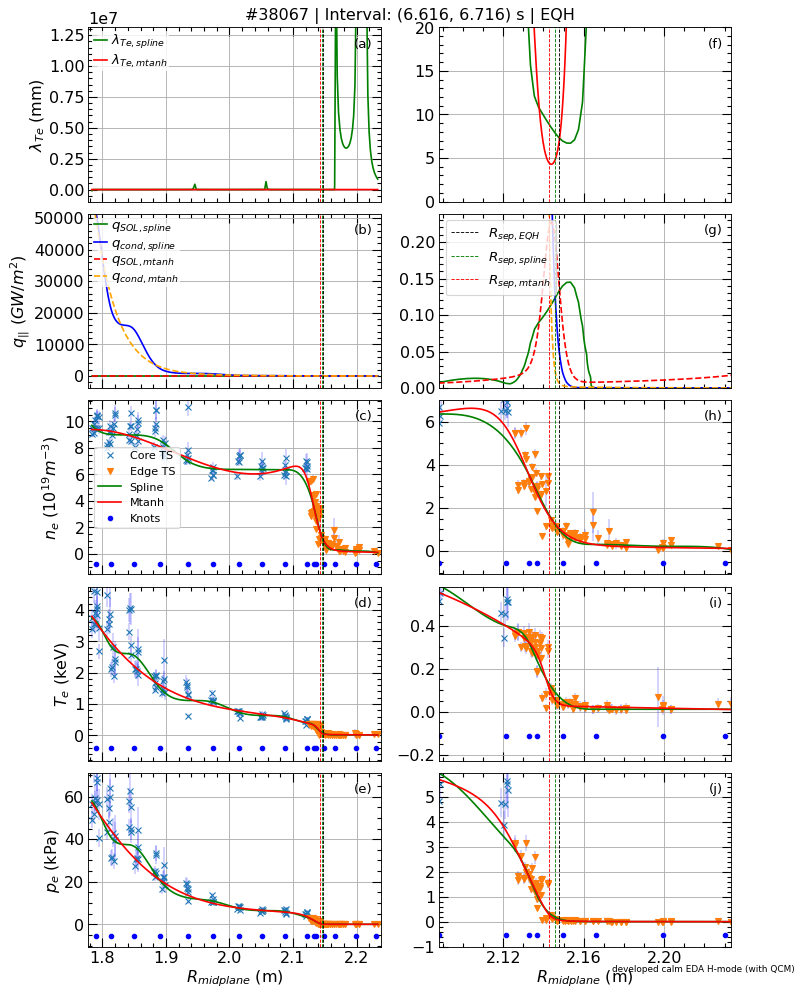

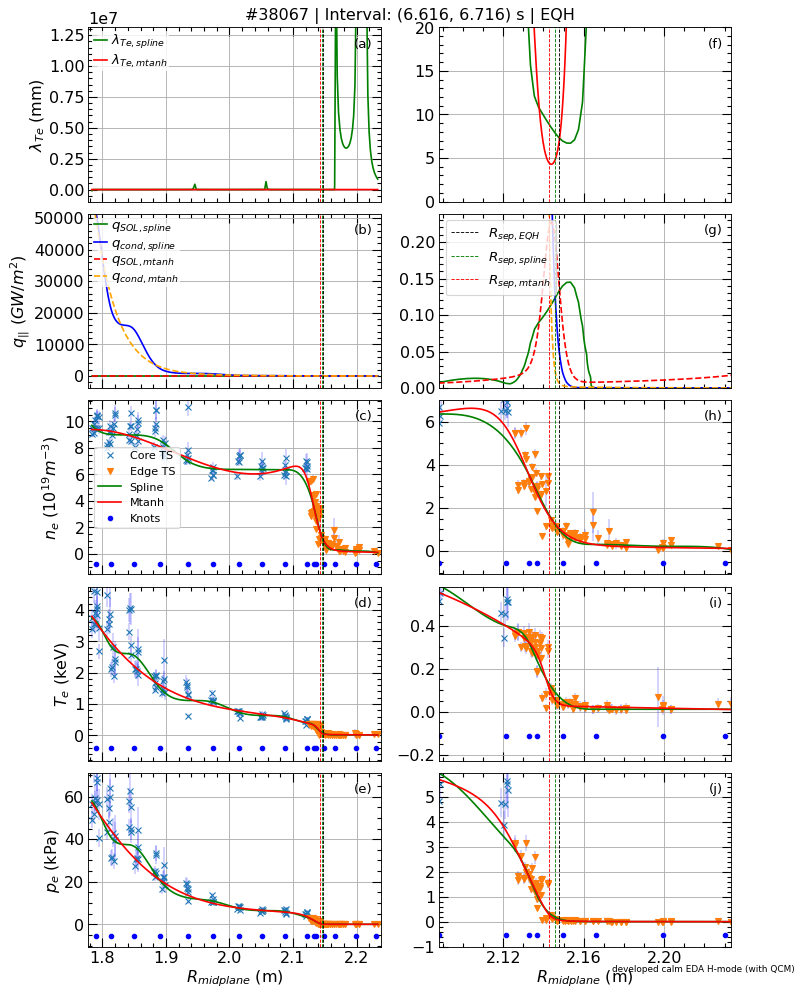

In [10]:
df_plot_te = ts_df.dropna(subset=['system', 'r_midplane', 'Te', 'Te_err', 'time'])
df_plot_ne = ts_df.dropna(subset=['system', 'r_midplane', 'Ne', 'Ne_err', 'time'])
core_te = df_plot_te['system'] == 'core'
edge_te = df_plot_te['system'] == 'edge'
core_ne = df_plot_ne['system'] == 'core'
edge_ne = df_plot_ne['system'] == 'edge'

summary_fig, summary_axes = plot_profile_summary(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    ne_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    ne_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    te_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    te_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    ne_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    ne_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    te_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    te_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    ds_out=ds_base,
    R_spline=spline_result['R_grid'],
    R_mtanh=mtanh_result['R_grid'],
    te_popt=te_popt,
    ne_popt=ne_popt,
    lambda_spline=spline_result['lam_Te_grid'],
    lambda_mtanh=mtanh_result['lam_Te_grid'],
    q_sol_spline=spline_result['q_par_P_SOL_grid'],
    q_cond_spline=spline_result['q_par_SH_grid'],
    q_sol_mtanh=mtanh_result['q_par_P_SOL_grid'],
    q_cond_mtanh=mtanh_result['q_par_SH_grid'],
    q_intersection_values=[spline_result['q_par_P_SOL'], mtanh_result['q_par_P_SOL']],
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    knot_pos=base_knots,
    nshot=shot_id,
    interval=interval,
    equilibrium=equilibrium,
    r_zoom=R_ZOOM,
    directory=output_directory,
    fig_name=make_fig_name(shot_id, equilibrium, base_knots.size, interval, 'summary_all'),
    save_fig=False,
    close=False,
    show=False,
)
summary_axes[0][1].set_ylim(0, 20)  # edge-zoom limit, as in the pinned notebook
summary_fig

### Scan

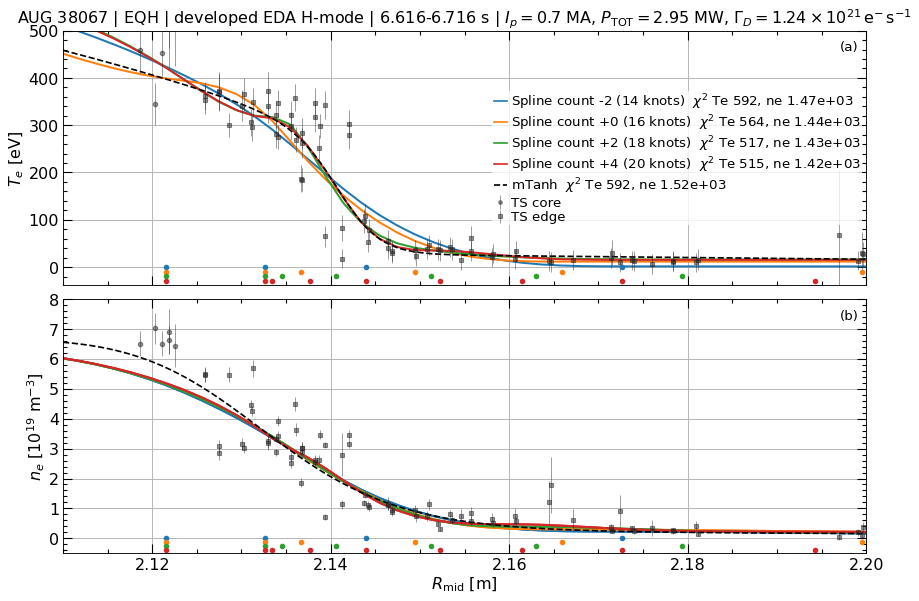

In [11]:
x_lo, x_hi = 2.11, 2.20
ok_shifts = [shift for shift in KNOT_COUNT_SHIFTS if shift in spline_fits]
shift_colors = [plt.get_cmap('tab10')(i) for i in range(len(ok_shifts))]

spline_lo = max(spline_fits[s]['ds_out']['R_mid_spl'].min() for s in ok_shifts)
spline_hi = min(spline_fits[s]['ds_out']['R_mid_spl'].max() for s in ok_shifts)
R_plot = np.linspace(max(x_lo, spline_lo), min(x_hi, spline_hi), 300)
ts_window = ts_df[ts_df['r_midplane'].between(x_lo, x_hi)]

datasets = []  # box 0 is Te, box 1 is ne in 1e19 m^-3


def add_dataset(x, y, box, label=None, ey=None, color='k', linestyle='-', linewidth=1.8,
                marker=None, markersize=None, alpha = 1.0):
    datasets.append(dict(
        x=np.asarray(x, dtype=float), y=np.asarray(y, dtype=float),
        ey=None if ey is None else np.asarray(ey, dtype=float), box=box, label=label,
        linestyle=linestyle, linewidth=linewidth, marker=marker, markersize=markersize,
        plot_kw={'color': color, 'alpha': alpha},
    ))


CHI2_TAG = r'$\chi^2$'


def reduced_chi2(df, value_col, error_col, model, n_parameters):
    # Same metric as the pipeline fit_metrics, over all TS points used in the fit.
    metrics = compute_fit_metrics(df[value_col].to_numpy(float), np.asarray(model, dtype=float),
                                  df[error_col].to_numpy(float), n_parameters=n_parameters)
    #print(metrics.keys())
    return metrics['weighted_sse']


def fit_label(name, te_chi2, ne_chi2):
    return f'{name}  {CHI2_TAG} Te {te_chi2:.3g}, ne {ne_chi2:.3g}'


def mtanh_parameter_count(quantity):
    cfg = mtanh_config[quantity]
    return count_modified_tanh_parameters(
        deg_tail=cfg.get('deg_tail', 3), deg_top=cfg.get('deg_top', 3),
        fix_x0=cfg.get('fix_x0'), fix_w=cfg.get('fix_w'), fix_a_tail=cfg.get('fix_a_tail'),
    )


for color, shift in zip(shift_colors, ok_shifts):
    ds = spline_fits[shift]['ds_out']
    r_spl = ds['R_mid_spl'].to_numpy()
    te_spl, ne_spl = ds['Te_spl'].to_numpy(), ds['ne_spl'].to_numpy()
    n_coeff = len(ds.attrs['t_full']) - 4  # cubic B-spline: coefficients = knot vector length - 4
    te_chi2 = reduced_chi2(df_te, 'Te', 'Te_err',
                           np.interp(df_te['r_midplane'].to_numpy(float), r_spl, te_spl), n_coeff)
    ne_chi2 = reduced_chi2(df_ne, 'Ne', 'Ne_err',
                           np.interp(df_ne['r_midplane'].to_numpy(float), r_spl, ne_spl), n_coeff)
    label = fit_label(f"Spline count {shift:+d} ({spline_fits[shift]['knots'].size} knots)",
                      te_chi2, ne_chi2)
    add_dataset(R_plot, np.interp(R_plot, r_spl, te_spl), box=0, label=label, color=color)
    add_dataset(R_plot, np.interp(R_plot, r_spl, ne_spl) / 1e19, box=1, color=color)
    add_dataset(R_plot, np.interp(R_plot, r_spl, ne_spl) / 1e19, box=1, color=color)

te_mtanh_chi2 = reduced_chi2(df_te, 'Te', 'Te_err',
                             modified_tanh(df_te['r_midplane'].to_numpy(float), *te_popt),
                             mtanh_parameter_count('Te'))
ne_mtanh_chi2 = reduced_chi2(df_ne, 'Ne', 'Ne_err',
                             modified_tanh(df_ne['r_midplane'].to_numpy(float), *ne_popt),
                             mtanh_parameter_count('Ne'))
add_dataset(R_plot, modified_tanh(R_plot, *te_popt), box=0,
            label=fit_label('mTanh', te_mtanh_chi2, ne_mtanh_chi2), color='black',
            linestyle='--', linewidth=1.5)
add_dataset(R_plot, modified_tanh(R_plot, *ne_popt) / 1e19, box=1, color='black',
            linestyle='--', linewidth=1.5)

for system, marker in [('core', 'o'), ('edge', 's')]:
    system_rows = ts_window[ts_window['system'] == system]
    te_rows = system_rows.dropna(subset=['Te', 'Te_err'])
    ne_rows = system_rows.dropna(subset=['Ne', 'Ne_err'])
    add_dataset(te_rows['r_midplane'], te_rows['Te'], box=0, label=f'TS {system}',
                ey=te_rows['Te_err'], color='0.15', linestyle='', marker=marker, markersize=4, alpha=0.5)
    add_dataset(ne_rows['r_midplane'], ne_rows['Ne'] / 1e19, box=1,
                ey=ne_rows['Ne_err'] / 1e19, color='0.15', linestyle='', marker=marker, markersize=4, alpha=0.5)

# Knot rows sit below zero so they do not overlap the data, one row per shift.
te_top = 1.2 * max(np.nanmax(d['y']) for d in datasets if d['box'] == 0)
ne_top = 1.2 * max(np.nanmax(d['y']) for d in datasets if d['box'] == 1)
te_row, ne_row = 0.06 * te_top, 0.06 * ne_top
for row, (color, shift) in enumerate(zip(shift_colors, ok_shifts)):
    knots = spline_fits[shift]['knots']
    knots = knots[(knots >= x_lo) & (knots <= x_hi)]
    add_dataset(knots, np.full(knots.size, -(row ) * te_row*0.25), box=0, color=color,
                linestyle='', marker='o', markersize=4)
    add_dataset(knots, np.full(knots.size, -(row ) * ne_row*0.25), box=1, color=color,
                linestyle='', marker='o', markersize=4)

fig, _ = ipfn_plots(
    x=[d['x'] for d in datasets],
    y=[d['y'] for d in datasets],
    ey=[d['ey'] for d in datasets],
    labels=[d['label'] for d in datasets],
    boxes=[d['box'] for d in datasets],
    linestyles=[d['linestyle'] for d in datasets],
    linewidths=[d['linewidth'] for d in datasets],
    markers=[d['marker'] for d in datasets],
    markersizes=[d['markersize'] for d in datasets],
    elinewidths=[0.8] * len(datasets),
    plot_kw=[d['plot_kw'] for d in datasets],
    n_boxes=2,
    x_mins_boxes=[x_lo, x_lo],
    x_maxs_boxes=[x_hi, x_hi],
    y_mins_boxes=[-(len(ok_shifts)) * te_row*0.25, -(len(ok_shifts)) * ne_row*0.25],
    y_maxs_boxes=[500,8],
    x_labels=[None,r'$R_{\mathrm{mid}}$ [m]'],
    y_labels=[r'$T_e$ [eV]', r'$n_e$ [$10^{19}$ m$^{-3}$]'],
    legend_kw=dict(loc='best'),
    title=(
        f"AUG {shot_id} | {equilibrium} | {interval['merged_label']} | {interval['t_begin']:.3f}-{interval['t_end']:.3f} s | "
        #f"edge window {x_lo:.2f}-{x_hi:.2f} m"
        f'{actuators_label}'
    ),
    show=False,
    save_fig=False,
    close=False,
    ncols=1,
    sharex=True,
    v_factor=1.8,
    h_factor=1.8,
)
fig


In [12]:
plots[]

SyntaxError: invalid syntax (321262282.py, line 1)

In [ ]:
output_directory

PosixPath('/shares/users/work/joanune/Desktop/TS_profile_fitter/plots')

In [ ]:
from ipfnpytools.save_figure import save_figure as save_fig
save_fig(fig, f"AUG_{shot_id}_{equilibrium}_{interval['label']}_{interval['t_begin']:.3f}-{interval['t_end']:.3f}_knot_shift_scan",
 format = 'pdf', directory = '/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Profile_Fitting/figures')

Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Profile_Fitting/figures/AUG_38049_EQH_L-mode_2.875-2.972_knot_shift_scan.pdf


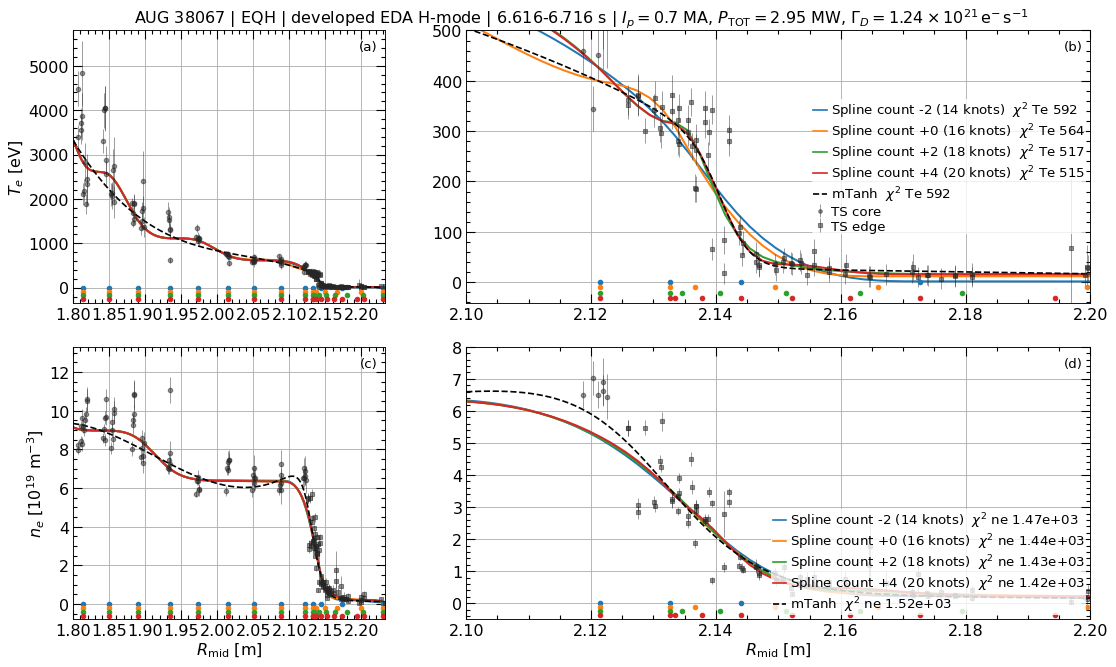

In [13]:
x_lo, x_hi = 2.10, 2.20
ok_shifts = [shift for shift in KNOT_COUNT_SHIFTS if shift in spline_fits]
shift_colors = [plt.get_cmap('tab10')(i) for i in range(len(ok_shifts))]

spline_lo = max(spline_fits[s]['ds_out']['R_mid_spl'].min() for s in ok_shifts)
spline_lo = 1.8
spline_hi = min(spline_fits[s]['ds_out']['R_mid_spl'].max() for s in ok_shifts)

# Grid: row 0 = Te, row 1 = ne; column 0 = full profile, column 1 = edge zoom.
VIEW_RANGE = {'full': (spline_lo, spline_hi), 'zoom': (max(x_lo, spline_lo), min(x_hi, spline_hi))}
BOX = {('Te', 'full'): 0, ('Te', 'zoom'): 1, ('ne', 'full'): 2, ('ne', 'zoom'): 3}
BOX_VIEW = ['full', 'zoom', 'full', 'zoom']
FIXED_YMAX = {1: 500, 3: 8}  # zoom limits, as in the pinned notebook
ZOOM_WIDTH_RATIO = 2  # zoom column width relative to the full-profile column


datasets = []


def add_dataset(x, y, box, label=None, ey=None, color='k', linestyle='-', linewidth=1.8,
                marker=None, markersize=None, alpha=1.0):
    datasets.append(dict(
        x=np.asarray(x, dtype=float), y=np.asarray(y, dtype=float),
        ey=None if ey is None else np.asarray(ey, dtype=float), box=box, label=label,
        linestyle=linestyle, linewidth=linewidth, marker=marker, markersize=markersize,
        plot_kw={'color': color, 'alpha': alpha},
    ))


CHI2_TAG = r'$\chi^2$'


def reduced_chi2(df, value_col, error_col, model, n_parameters):
    metrics = compute_fit_metrics(df[value_col].to_numpy(float), np.asarray(model, dtype=float),
                                  df[error_col].to_numpy(float), n_parameters=n_parameters)
    return metrics['weighted_sse']


def fit_label(name, quantity, chi2):
    return f'{name}  {CHI2_TAG} {quantity} {chi2:.3g}'


def mtanh_parameter_count(quantity):
    cfg = mtanh_config[quantity]
    return count_modified_tanh_parameters(
        deg_tail=cfg.get('deg_tail', 3), deg_top=cfg.get('deg_top', 3),
        fix_x0=cfg.get('fix_x0'), fix_w=cfg.get('fix_w'), fix_a_tail=cfg.get('fix_a_tail'),
    )


# Chi2 labels use all TS points in the fit, so they do not depend on the view.
spline_labels = {}
for shift in ok_shifts:
    ds = spline_fits[shift]['ds_out']
    r_spl = ds['R_mid_spl'].to_numpy()
    n_coeff = len(ds.attrs['t_full']) - 4  # cubic B-spline: coefficients = knot vector length - 4
    te_chi2 = reduced_chi2(df_te, 'Te', 'Te_err',
                           np.interp(df_te['r_midplane'].to_numpy(float), r_spl, ds['Te_spl'].to_numpy()), n_coeff)
    ne_chi2 = reduced_chi2(df_ne, 'Ne', 'Ne_err',
                           np.interp(df_ne['r_midplane'].to_numpy(float), r_spl, ds['ne_spl'].to_numpy()), n_coeff)
    name = f"Spline count {shift:+d} ({spline_fits[shift]['knots'].size} knots)"
    spline_labels[shift] = {"Te": fit_label(name, "Te", te_chi2), "ne": fit_label(name, "ne", ne_chi2)}

te_mtanh_chi2 = reduced_chi2(df_te, 'Te', 'Te_err',
                             modified_tanh(df_te['r_midplane'].to_numpy(float), *te_popt),
                             mtanh_parameter_count('Te'))
ne_mtanh_chi2 = reduced_chi2(df_ne, 'Ne', 'Ne_err',
                             modified_tanh(df_ne['r_midplane'].to_numpy(float), *ne_popt),
                             mtanh_parameter_count('Ne'))
mtanh_label = {'Te': fit_label('mTanh', 'Te', te_mtanh_chi2), 'ne': fit_label('mTanh', 'ne', ne_mtanh_chi2)}

for view, (x_min, x_max) in VIEW_RANGE.items():
    R_plot = np.linspace(x_min, x_max, 300)
    ts_view = ts_df[ts_df['r_midplane'].between(x_min, x_max)]
    te_box, ne_box = BOX[('Te', view)], BOX[('ne', view)]

    for color, shift in zip(shift_colors, ok_shifts):
        ds = spline_fits[shift]['ds_out']
        r_spl = ds['R_mid_spl'].to_numpy()
        add_dataset(R_plot, np.interp(R_plot, r_spl, ds['Te_spl'].to_numpy()), box=te_box,
                    label=spline_labels[shift]['Te'], color=color)
        add_dataset(R_plot, np.interp(R_plot, r_spl, ds['ne_spl'].to_numpy()) / 1e19, box=ne_box, label=spline_labels[shift]['ne'], color=color)

    add_dataset(R_plot, modified_tanh(R_plot, *te_popt), box=te_box, label=mtanh_label['Te'],
                color='black', linestyle='--', linewidth=1.5)
    add_dataset(R_plot, modified_tanh(R_plot, *ne_popt) / 1e19, box=ne_box, label=mtanh_label['ne'],
                color='black', linestyle='--', linewidth=1.5)

    for system, marker in [('core', 'o'), ('edge', 's')]:
        system_rows = ts_view[ts_view['system'] == system]
        te_rows = system_rows.dropna(subset=['Te', 'Te_err'])
        ne_rows = system_rows.dropna(subset=['Ne', 'Ne_err'])
        add_dataset(te_rows['r_midplane'], te_rows['Te'], box=te_box, label=f'TS {system}',
                    ey=te_rows['Te_err'], color='0.15', linestyle='', marker=marker, markersize=4, alpha=0.5)
        add_dataset(ne_rows['r_midplane'], ne_rows['Ne'] / 1e19, box=ne_box,
                    ey=ne_rows['Ne_err'] / 1e19, color='0.15', linestyle='', marker=marker, markersize=4, alpha=0.5)

panel_top = {box: 1.2 * max(np.nanmax(d['y']) for d in datasets if d['box'] == box) for box in range(4)}

# Knot rows sit below zero so they do not overlap the data, one row per shift.
for row_idx, (color, shift) in enumerate(zip(shift_colors, ok_shifts)):
    knots = spline_fits[shift]['knots']
    for view, (x_min, x_max) in VIEW_RANGE.items():
        knots_view = knots[(knots >= x_min) & (knots <= x_max)]
        for quantity in ('Te', 'ne'):
            box = BOX[(quantity, view)]
            step = 0.015 * panel_top[box]
            add_dataset(knots_view, np.full(knots_view.size, -row_idx * step), box=box, color=color,
                        linestyle='', marker='o', markersize=4)

fig, _ = ipfn_plots(
    x=[d['x'] for d in datasets],
    y=[d['y'] for d in datasets],
    ey=[d['ey'] for d in datasets],
    labels=[d['label'] for d in datasets],
    boxes=[d['box'] for d in datasets],
    linestyles=[d['linestyle'] for d in datasets],
    linewidths=[d['linewidth'] for d in datasets],
    markers=[d['marker'] for d in datasets],
    markersizes=[d['markersize'] for d in datasets],
    elinewidths=[0.8] * len(datasets),
    plot_kw=[d['plot_kw'] for d in datasets],
    n_boxes=4,
    nrows=2,
    ncols=2,
    order='row',
    x_mins_boxes=[VIEW_RANGE[v][0] for v in BOX_VIEW],
    x_maxs_boxes=[VIEW_RANGE[v][1] for v in BOX_VIEW],
    y_mins_boxes=[-len(ok_shifts) * 0.015 * panel_top[b] for b in range(4)],
    y_maxs_boxes=[FIXED_YMAX.get(b, panel_top[b]) for b in range(4)],
    x_labels=[None, None, r'$R_{\mathrm{mid}}$ [m]', r'$R_{\mathrm{mid}}$ [m]'],
    y_labels=[r'$T_e$ [eV]', None, r'$n_e$ [$10^{19}$ m$^{-3}$]', None],
    write_legends=[False, True, False, True],
    legend_kw=[dict(loc='best'), dict(loc='best'), dict(loc='lower right'), dict(loc='lower right')],
    title=(
        f"AUG {shot_id} | {equilibrium} | {interval['merged_label']} | {interval['t_begin']:.3f}-{interval['t_end']:.3f} s | "
        f'{actuators_label}'
    ),
    show=False,
    save_fig=False,
    close=False,
    sharex=False,
    v_factor=2,
    h_factor=2.2,
    gridspec_kw=dict(width_ratios=[1, ZOOM_WIDTH_RATIO]),
)
fig

In [ ]:
save_fig(fig, f"AUG_{shot_id}_{equilibrium}_{interval['merged_label']}_{interval['t_begin']:.3f}-{interval['t_end']:.3f}_knot_shift_scan_2x2",
 format = 'pdf', directory = '/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Profile_Fitting/figures')

Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Profile_Fitting/figures/AUG_38049_EQH_developed EDA H-mode_3.872-3.974_knot_shift_scan_2x2.pdf


In [ ]:
interval['merged_label']

'developed EDA H-mode'